<a href="https://colab.research.google.com/github/IrenaSpivak15/IrenaSpivak15/blob/claude%2Fphoto-avatar-7nfmuj/Copy_of_Code_01_XX_Question_Answering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import transformers

#Set to avoid warning messages.
transformers.logging.set_verbosity_error()

## 01.03. Using a Qu-An Pipeline

In [9]:
from transformers import pipeline

context="""
Earth is the third planet from the Sun and the only astronomical object
known to harbor life. While large volumes of water can be found
throughout the Solar System, only Earth sustains liquid surface water.
About 71% of Earth's surface is made up of the ocean, dwarfing
Earth's polar ice, lakes, and rivers. The remaining 29% of Earth's
surface is land, consisting of continents and islands.
Earth's surface layer is formed of several slowly moving tectonic plates,
interacting to produce mountain ranges, volcanoes, and earthquakes.
Earth's liquid outer core generates the magnetic field that shapes Earth's
magnetosphere, deflecting destructive solar winds.
"""

# Using the modern text-generation pipeline with an instruction-following model
quan_pipeline = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct", device_map="auto")

def ask_question(question, context):
    messages = [
        {"role": "system", "content": "Answer the user's question concisely using only the provided context."},
        {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"}
    ]
    outputs = quan_pipeline(messages, max_new_tokens=50, return_full_text=False)
    return outputs[0]['generated_text']

answer = ask_question("How much of earth is land?", context)
print("\n\nAnswer:", answer)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]



Answer: The given text states that about 29% of Earth's surface is land.


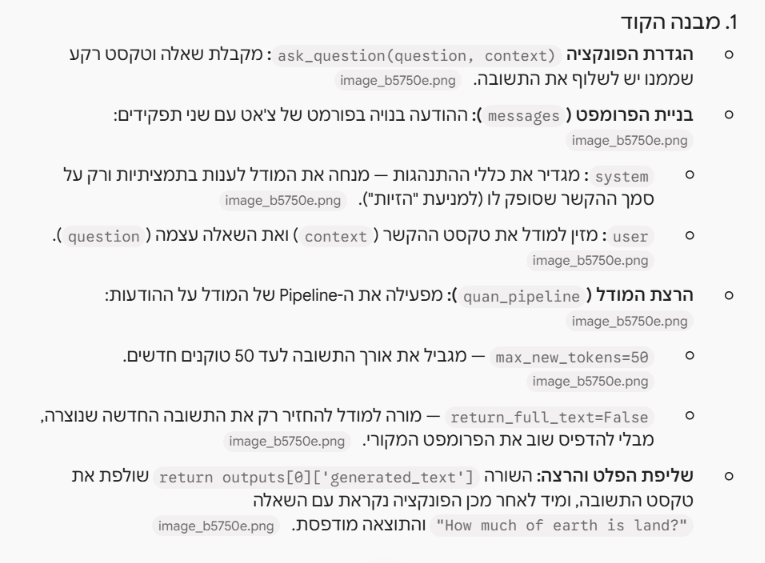

In [10]:
print("\nAnother question :")
print(ask_question("How are mountain ranges created?", context))


Another question :
Mountain ranges are created by the slow movement of tectonic plates on the Earth's surface.


## 01.05 Evaluating Qu-An Performance

In [11]:
!pip install evaluate
from evaluate import load
squad_metric = load("squad_v2")

#Ignoring Context & Question as they are not needed for evaluation
#This example is to showcase how the evaluation works based on match between the prediction
#and the correct answer

correct_answer="Paris"

predicted_answers=["Paris",
                 "London",
                 "Paris is one of the best cities in the world"]

cum_predictions=[]
cum_references=[]
for i in range(len(predicted_answers)):

    #Use the input format for predictions
    predictions = [{'prediction_text':predicted_answers[i],
                    'id': str(i),
                    'no_answer_probability': 0.}]
    cum_predictions.append(predictions[0])

    #Use the input format for naswers
    references = [{'answers': {'answer_start': [1],
                               'text': [correct_answer]},
                   'id': str(i)}]
    cum_references.append(references[0])

    results = squad_metric.compute(predictions=predictions,references=references)
    print("F1 is", results.get('f1'), " for answer :", predicted_answers[i])

#Compute for cumulative Results
cum_results=squad_metric.compute(predictions=cum_predictions,references=cum_references)
print("\n Cumulative Results : \n",cum_results)

F1 is 100.0  for answer : Paris
F1 is 0.0  for answer : London
F1 is 22.22222222222222  for answer : Paris is one of the best cities in the world

 Cumulative Results : 
 {'exact': 33.333333333333336, 'f1': 40.74074074074074, 'total': 3, 'HasAns_exact': 33.333333333333336, 'HasAns_f1': 40.74074074074074, 'HasAns_total': 3, 'best_exact': 33.333333333333336, 'best_exact_thresh': 0.0, 'best_f1': 40.74074074074074, 'best_f1_thresh': 0.0}


In [12]:
import collections
import re
import string

def normalize_answer(s):
    """Lowercases, removes punctuation, articles, and extra whitespace."""
    def remove_articles(text):
        regex = re.compile(r'\b(a|an|the)\b', re.UNICODE)
        return re.sub(regex, ' ', text)
    def white_space_fix(text):
        return ' '.join(text.split())
    def remove_punc(text):
        exclude = set(string.punctuation)
        return ''.join(ch for ch in text if ch not in exclude)
    def lower(text):
        return text.lower()
    return white_space_fix(remove_articles(remove_punc(lower(s))))

def get_precision_recall_f1(prediction, reference):
    prediction_tokens = normalize_answer(prediction).split()
    reference_tokens = normalize_answer(reference).split()

    common = collections.Counter(prediction_tokens) & collections.Counter(reference_tokens)
    num_same = sum(common.values())

    if len(prediction_tokens) == 0 or len(reference_tokens) == 0:
        # If either is empty, but they match, it's a perfect score
        return int(prediction_tokens == reference_tokens), int(prediction_tokens == reference_tokens), int(prediction_tokens == reference_tokens)

    if num_same == 0:
        return 0.0, 0.0, 0.0

    precision = 100.0 * num_same / len(prediction_tokens)
    recall = 100.0 * num_same / len(reference_tokens)
    f1 = (2 * precision * recall) / (precision + recall)

    return precision, recall, f1

# Evaluate the predictions
for pred in predicted_answers:
    p, r, f = get_precision_recall_f1(pred, correct_answer)
    print(f"Prediction: '{pred}'")
    print(f"  -> Precision: {p:.2f}%")
    print(f"  -> Recall:    {r:.2f}%")
    print(f"  -> F1 Score:  {f:.2f}%\n")

Prediction: 'Paris'
  -> Precision: 100.00%
  -> Recall:    100.00%
  -> F1 Score:  100.00%

Prediction: 'London'
  -> Precision: 0.00%
  -> Recall:    0.00%
  -> F1 Score:  0.00%

Prediction: 'Paris is one of the best cities in the world'
  -> Precision: 12.50%
  -> Recall:    100.00%
  -> F1 Score:  22.22%



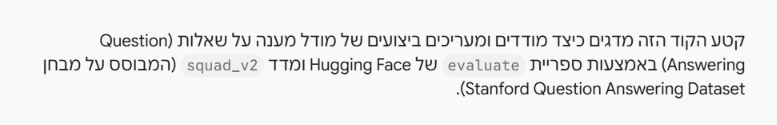